In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from scipy.signal import convolve2d, convolve
from gliders.utils import sigma_clipping, normalize_data
from astropy.convolution import Gaussian2DKernel, Gaussian1DKernel

def suppress_noise(image, method ="simple", kernel = None, logit_alpha = 1.0):
    """
    Suppress background-dominated pixels in an image using a noise-based
    probability model.

    The function assumes that image noise follows an approximately normal
    distribution. A noise probability map is first computed from the image
    intensity distribution and then refined using one of several methods.
    The resulting probability map is applied as a weighting function,
    enhancing statistically significant structures while attenuating pixels
    consistent with the background noise.

    Parameters
    ----------
    image : ndarray
        Input image.

    method : {'simple', 'logit', 'layers'}, optional
        Method used to generate the probability map.

        * ``'simple'``: spatial smoothing of the noise probability map.
        * ``'logit'``: smoothing in logit space followed by a logistic
          transformation.
        * ``'layers'``: iterative probability refinement using an
          additional intensity-weighted layer.

        Default is ``'simple'``.

    kernel : ndarray, optional
        Convolution kernel used for local probability aggregation. If
        ``None``, a ``Gaussian2DKernel(2.0)`` is used.

    logit_alpha : float, optional
        Scaling factor applied to the logistic transform when
        ``method='logit'``. Larger values increase the contrast between
        low- and high-probability regions.

    Returns
    -------
    ndarray
        Background-suppressed image rescaled to approximately match the
        original image intensity range.

    See Also
    --------
    get_p_simple
    get_p_logit
    get_p_layers
    apply_p_map
    """

    if kernel is None:
        kernel = Gaussian2DKernel(2.0) # Larger kernels yield higher noise level, but more symmetric noise distribution

    image_noise_lvl, image_noise_std = sigma_clipping(image, robust=False)

    # Probability of obtaining x or lower:
    noise_p_map = norm.cdf(image, loc=image_noise_lvl, scale=image_noise_std)  # sf = 1 - cdf = survival function

    if method == "logit":
        p_map = _get_p_logit(noise_p_map, kernel, alpha = logit_alpha)
    elif method == "layers":
        p_map = _get_p_layers(image, noise_p_map, kernel)
    else: #simple
        p_map = _get_p_simple(noise_p_map, kernel)

    bkg_reduced_image_leveled = _apply_p_map(image, p_map)

    return bkg_reduced_image_leveled

def _get_p_simple(p_map, kernel):
    """
    Convolve probability map (p_map) with the input kernel.
    """

    p_out = convolve2d(p_map, kernel, mode='same', boundary='symm')
    return p_out

def _get_p_logit(p_map, kernel, alpha = 1.0):
    """
    Transform probability map (p_map) into logits, convolve with the supplied
    kernel, and transform back into a probability map.

    alpha is the scaling factor applied to the aggregated logits before converting
    back to probabilities. Values greater than one amplify local contrast,
    while values less than one reduce it.

    Notes
    -----
    Pixels with probability equal to one are clipped slightly below one
    before the logit transformation to avoid numerical singularities.
    """

    p_map[p_map >= 1] = 1-1e-9
    logit = np.log(p_map / (1 - p_map))
    L = convolve2d(logit, kernel, mode='same', boundary='symm')  # weighted sum of logit
    p_out = 1.0 / (1.0 + np.exp(-alpha * L))
    return p_out

def _get_p_layers(image, p_map, kernel):
    """
    Generate a probability map using a two-layer probability refinement
    scheme.

    An initial probability map (p_map) is first convolved with the provided kernel.
    The image is then weighted by this smoothed map, and a second probability map is
    estimated from the resulting intensity distribution. The final output
    is obtained by combining the two probability layers.
    """

    p_map_cnv = convolve2d(p_map, kernel, mode='same', boundary='symm')
    image_p_map_cnv = image * p_map_cnv
    image_p_map_cnv_noise = sigma_clipping(image_p_map_cnv, robust=False)
    p_map_new_layer = norm.cdf(image_p_map_cnv, loc=image_p_map_cnv_noise[0], scale=image_p_map_cnv_noise[1])
    p_map_new_layer_cnv = convolve2d(p_map_new_layer, kernel, mode='same', boundary='symm')
    p_out = p_map_cnv * p_map_new_layer_cnv
    return p_out

def _apply_p_map(image, p_map):
    """
    Apply a probability map (p_map) to an image and rescale according to their maxima.
    """

    image_p_map = image * p_map
    image_p_map_leveled = image_p_map * image.max() / image_p_map.max()
    return image_p_map_leveled

def show_all_methods(image, kernel = None, normalize = True, cmap = "plasma", display_norm = "log", image_bias = 0.001, show_distributions = False):
    """
    Visualization of the different background-suppression methods available in the
    package.

    This utility function computes the probability maps and background-reduced
    images obtained with the ``simple``, ``logit``, and ``layers`` methods,
    and displays the results either as images or as intensity distributions.
    It is primarily intended for visual inspection, debugging, and parameter
    tuning.

    Parameters
    ----------
    image : ndarray
        Input image.

    kernel : ndarray, optional
        Convolution kernel used to smooth the probability maps. If ``None``,
        a ``Gaussian2DKernel(2.0)`` is used.

    normalize : bool, optional
        If ``True``, all displayed images are normalized using
        ``normalize_data`` before visualization. Default is ``True``.

    cmap : str, optional
        Matplotlib colormap used for image display. Default is ``"plasma"``.

    display_norm : str, optional
        Normalization used for image visualization and histogram scaling.
        Typical values are ``"log"`` and ``"linear"``. Default is ``"log"``.

    image_bias : float, optional
        Small positive value added to displayed images to avoid issues with
        logarithmic visualization and zero-valued pixels. Default is
        ``0.001``.

    show_distributions : bool, optional
        If ``True``, display intensity histograms of the original and
        processed images instead of image panels. Default is ``False``.

    Returns
    -------
    None
        The function generates matplotlib figures but does not return any
        value.

    See Also
    --------
    diminish_background
    get_p_simple
    get_p_logit
    get_p_layers
    apply_p_map
    normalize_data
    sigma_clipping
    """

    if kernel is None:
        kernel = Gaussian2DKernel(2.0)
    image_noise_lvl, image_noise_std = sigma_clipping(image, robust=False)
    p_map = norm.cdf(image, loc=image_noise_lvl, scale=image_noise_std)  # sf = 1 - cdf = survival function

    p_simple = _get_p_simple(p_map, kernel)
    p_logit = _get_p_logit(p_map, kernel)
    p_layers = _get_p_layers(image, p_map, kernel)

    bkg_reduced_image_simple = _apply_p_map(image, p_simple)
    bkg_reduced_image_logit = _apply_p_map(image, p_logit)
    bkg_reduced_image_layers = _apply_p_map(image, p_layers)

    images = {
        'im_original': image,
        'im_simple': bkg_reduced_image_simple,
        'im_logit': bkg_reduced_image_logit,
        'im_layers': bkg_reduced_image_layers,
    }

    if normalize:
        for key in images:
            images[key] = normalize_data(images[key]) + image_bias

    if show_distributions:

        image_hist = images['im_original'].flatten()
        bins = np.logspace(np.log10(np.min(image_hist[image_hist>0])),np.log10(np.max(image_hist)),100)
        for key in images:
            log_y = False
            if display_norm == "log":
                log_y = True
            plt.hist(images[key].flatten(), bins = bins, alpha = 0.8, log = log_y, histtype='step', label = key, linewidth = 3, density = False)
        plt.xscale(display_norm)
        plt.legend()
        plt.show()

    else:

        if not normalize:
            for key in images:
                images[key] += image_bias

        figs, ax = plt.subplots(2, 4, layout="tight")

        ax[1, 0].imshow(p_map, origin="lower")
        ax[1, 0].set_title("raw p_map")
        ax[0, 0].imshow(images["im_original"], origin="lower", norm=display_norm, cmap=cmap)
        ax[0, 0].set_title("original")

        ax[1, 1].imshow(p_simple, origin="lower")
        ax[1, 1].set_title("simple")
        ax[0, 1].imshow(images["im_simple"], origin="lower", norm=display_norm, cmap=cmap)
        ax[0, 1].set_title("simple")

        ax[1, 2].imshow(p_logit, origin="lower")
        ax[1, 2].set_title("logit")
        ax[0, 2].imshow(images["im_logit"], origin="lower", norm=display_norm, cmap=cmap)
        ax[0, 2].set_title("logit")

        ax[1, 3].imshow(p_layers, origin="lower")
        ax[1, 3].set_title("layers")
        ax[0, 3].imshow(images["im_layers"], origin="lower", norm=display_norm, cmap=cmap)
        ax[0, 3].set_title("layers")

        plt.show()







<TableColumns names=('WAVELENGTH','FLUX')>


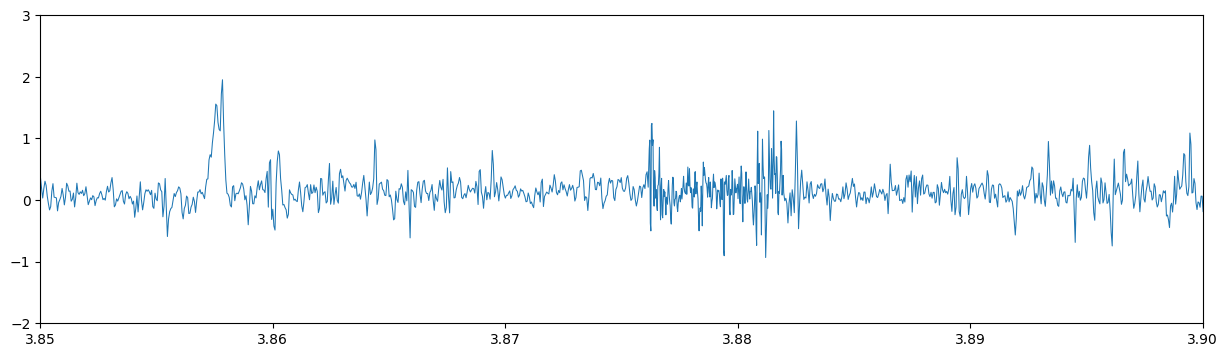

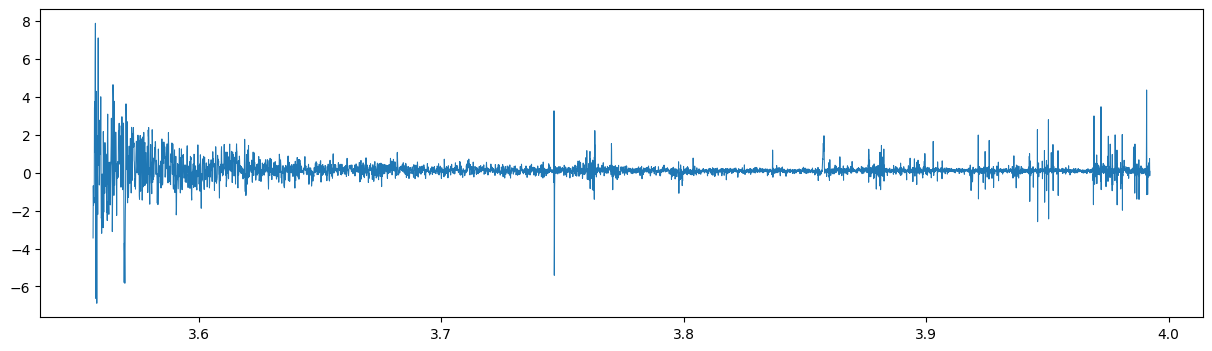

3.5573146
3.5573146
7957


In [5]:
import os
from astropy.io import fits
from astropy.table import Table
import numpy as np
work_dir = "C:/Users/Alejandro/Desktop"
#filename = 'spec-10448-58158-0014.fits'
filename = '39633427959382977_combined_spectrum.fits'
fits_path = os.path.join(work_dir, filename)
with fits.open(fits_path, memmap=True) as hdu_list:
    data_table = Table(hdu_list[1].data, copy=False)


def _get_p_simple_1D(p_map, kernel):
    p_out = convolve(p_map, kernel, mode='same')
    return p_out

def _get_p_logit_1D(p_map, kernel, alpha = 1.0):
    p_map[p_map >= 1] = 1-1e-9
    logit = np.log(p_map / (1 - p_map))
    L = convolve(logit, kernel, mode='same')  # weighted sum of logit
    p_out = 1.0 / (1.0 + np.exp(-alpha * L))
    return p_out

def _get_p_layers_1D(data, p_map, kernel):
    p_map_cnv = convolve(p_map, kernel, mode='same')
    data_p_map_cnv = data * p_map_cnv
    data_p_map_cnv_noise = sigma_clipping(data_p_map_cnv, robust=False)
    data_p_map_cnv_center = data_p_map_cnv - data_p_map_cnv_noise[0]
    # p_map_new_layer = norm.cdf(data_p_map_cnv, loc=data_p_map_cnv_noise[0], scale=data_p_map_cnv_noise[1])
    p_map_new_layer = norm.cdf(data_p_map_cnv_center**2, loc=0, scale=data_p_map_cnv_noise[1])
    p_map_new_layer_cnv = convolve(p_map_new_layer, kernel, mode='same')
    p_out = p_map_cnv * p_map_new_layer_cnv
    return p_out

def _apply_p_profile(data, p_map):
    """
    Apply a probability map (p_map) to an image and rescale according to their maxima.
    """

    data_p_map = data * p_map
    data_p_map_leveled = data_p_map * data.max() / data_p_map.max()
    return data_p_map_leveled

def smoothen_data(level = 1, x = None, y = None):
    smooth_x, smooth_y = x, y
    for i in range(level):
        smooth_y = (smooth_y[0:-1] + smooth_y[1:])/2
        smooth_x = (smooth_x[0:-1] + smooth_x[1:])/2
    return smooth_x, smooth_y

print(data_table.columns)

#data_table['log'] = 10*data_table['loglam']

#x, y = data_table['loglam'], data_table['flux']
x, y = data_table['WAVELENGTH'], data_table['FLUX']
#smooth_x, smooth_y = smoothen_data(level = 1, x = 10**x, y = y)
smooth_x, smooth_y = smoothen_data(level = 1, x = x, y = y)
smooth_x = np.log10(smooth_x)

x, y = smooth_x, smooth_y

kernel = Gaussian1DKernel(3.0) # Larger kernels yield higher noise level, but more symmetric noise distribution
y_noise_lvl, y_noise_std = sigma_clipping(y, robust=False)

y_centered = y - y_noise_lvl
# noise_p_map = norm.cdf(y, loc=y_noise_lvl, scale=y_noise_std)  # sf = 1 - cdf = survival function
noise_p_map = norm.cdf(y_centered**2, loc=0, scale=y_noise_std)  # sf = 1 - cdf = survival function
# noise_p_map = norm.pdf(y, loc=y_noise_lvl, scale=y_noise_std)  # sf = 1 - cdf = survival function

p_simple = _get_p_simple_1D(noise_p_map, kernel)
p_logit = _get_p_logit_1D(noise_p_map, kernel)
p_layers = _get_p_layers_1D(y, noise_p_map, kernel)

y_simple = _apply_p_profile(y_centered,p_simple) + y_noise_lvl
y_logit = _apply_p_profile(y_centered,p_logit) + y_noise_lvl
y_layers = _apply_p_profile(y_centered,p_layers) + y_noise_lvl

# x_logit_smooth, y_logit_smooth = smoothen_data(level = 80, x = 10**x, y = y_logit)
# x_logit_smooth = np.log10(x_logit_smooth)

figsize = (15,4)
linew = 0.75
lo_lim_x = 3.85
hi_lim_x = 3.9
lo_lim_y = -2
hi_lim_y = 3
plt.figure(figsize = figsize)
plt.plot(x,y, lw = linew)
plt.xlim(lo_lim_x,hi_lim_x)
plt.ylim(lo_lim_y,hi_lim_y)
plt.show()
#plt.figure(figsize = figsize)
#plt.plot(x, y_simple, lw = linew)
#plt.show()
plt.figure(figsize = figsize)
plt.plot(x, y_logit, lw = linew)
# plt.xlim(lo_lim_x,hi_lim_x)
# plt.ylim(lo_lim_y,hi_lim_y)
plt.show()
#plt.figure(figsize = figsize)
#plt.plot(x, y_layers, lw = linew)
# plt.show()

# plt.figure(figsize = (15,4))
# plt.plot(smooth_x, smooth_y, lw = 1)
# plt.show()
# plt.figure(figsize = (15,4))
# plt.plot(x_logit_smooth, y_logit_smooth, lw = 1)
# plt.show()

print(x[np.argmax(y)])
print(smooth_x[np.argmax(smooth_y)])
print(len(x))
